# Candidate-agent evaluation and four-way tournament

This notebook evaluates four frozen candidates on the same Task 1–4 suite, then runs a separate four-way tournament among the three DDQN candidates and `rule_based_agent`. It changes neither training logic nor checkpoints.

**Primary decision metric:** Task 4 candidate `mean_score` against three `rule_based_agent`s. The remaining metrics diagnose the reason for a score difference.

## 1. Setup

Run from the project root or from `notebooks/`. Install missing analysis packages into the active `ml_essential` kernel with `python -m pip install pandas seaborn matplotlib`.

In [1]:
from __future__ import annotations

import json
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')

def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'main.py').exists() and (candidate / 'agent_code').exists():
            return candidate
    raise FileNotFoundError('Project root not found. Open this notebook from the project root or its notebooks/ folder.')

ROOT = find_project_root()
RESULT_DIR = ROOT / 'results' / 'evaluation_runs'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

CANDIDATES = [
    'dueling_ddqn_agent',
    'frozen_ddqn_day7',
    'frozen_ddqn_day11',
    'linear_q_agent',
]

missing = [agent for agent in CANDIDATES if not (ROOT / 'agent_code' / agent).is_dir()]
assert not missing, f'Missing agent folders: {missing}'
print(f'Project root: {ROOT}')
print('Candidates:', ', '.join(CANDIDATES))

Project root: <PROJECT_ROOT>
Candidates: dueling_ddqn_agent, frozen_ddqn_day7, frozen_ddqn_day11, linear_q_agent


## 2. Frozen task suite

Every candidate receives exactly the same scenario, opponents, number of rounds, and seed. Do not use the final Task-4 seed repeatedly for tuning; reserve a fresh locked seed set for the final promotion decision.

In [2]:
TASKS = [
    dict(task='Task 1', label='coin_heaven', scenario='coin-heaven', rounds=20, seed=8102, opponents=[]),
    dict(task='Task 2', label='classic_solo', scenario='classic', rounds=20, seed=8201, opponents=[]),
    dict(task='Task 3', label='peaceful', scenario='classic', rounds=20, seed=8301, opponents=['peaceful_agent'] * 3),
    dict(task='Task 3', label='coin_collectors', scenario='classic', rounds=20, seed=8302, opponents=['coin_collector_agent'] * 3),
    dict(task='Task 4', label='rule_based', scenario='classic', rounds=50, seed=9801, opponents=['rule_based_agent'] * 3),
    dict(task='Task 4', label='mixed', scenario='classic', rounds=20, seed=8306, opponents=['peaceful_agent', 'coin_collector_agent', 'rule_based_agent']),
]

display(pd.DataFrame(TASKS)[['task', 'label', 'scenario', 'rounds', 'seed', 'opponents']])

,task,label,scenario,rounds,seed,opponents
0,Task 1,coin_heaven,coin-heaven,20,8102,[]
1,Task 2,classic_solo,classic,20,8201,[]
2,Task 3,peaceful,classic,20,8301,"[peaceful_agent, peaceful_agent, peaceful_agent]"
3,Task 3,coin_collectors,classic,20,8302,"[coin_collector_agent, coin_collector_agent, c..."
4,Task 4,rule_based,classic,50,9801,"[rule_based_agent, rule_based_agent, rule_base..."
5,Task 4,mixed,classic,20,8306,"[peaceful_agent, coin_collector_agent, rule_ba..."


## 3. Run the complete suite for all four candidates

Set `RUN_CANDIDATE_SUITE = True` to launch games. Existing output files are reused unless `FORCE_RERUN = True`. Evaluation calls `main.py play` without `--train 1`, so it does not update weights or collect training experience.

In [6]:
RUN_CANDIDATE_SUITE = True
FORCE_RERUN = False
RUN_TAG = 'candidate_screening_v1'

def safe_name(name: str) -> str:
    return name.replace(' ', '_').replace('-', '_')

def suite_raw_path(agent: str, spec: dict) -> Path:
    return RESULT_DIR / (f"{RUN_TAG}_{agent}_{safe_name(spec['task'])}_{spec['label']}_seed{spec['seed']}.json")

def run_game(agent: str, spec: dict) -> Path:
    output = suite_raw_path(agent, spec)
    if output.exists() and not FORCE_RERUN:
        print(f'Reusing: {output.name}')
        return output
    command = [
        sys.executable, 'main.py', 'play', '--no-gui', '--agents', agent, *spec['opponents'],
        '--scenario', spec['scenario'], '--n-rounds', str(spec['rounds']),
        '--seed', str(spec['seed']), '--save-stats', str(output),
    ]
    print('Running:', ' '.join(command))
    subprocess.run(command, cwd=ROOT, check=True)
    return output

if RUN_CANDIDATE_SUITE:
    suite_paths = {(agent, spec['task'], spec['label']): run_game(agent, spec)
                   for agent in CANDIDATES for spec in TASKS}
else:
    suite_paths = {(agent, spec['task'], spec['label']): suite_raw_path(agent, spec)
                   for agent in CANDIDATES for spec in TASKS}
    print('No games launched. Set RUN_CANDIDATE_SUITE = True to run the full screening suite.')

Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent --scenario coin-heaven --n-rounds 20 --seed 8102 --save-stats <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_dueling_ddqn_agent_Task_1_coin_heaven_seed8102.json


100%|██████████| 20/20 [00:06<00:00,  3.02it/s]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent --scenario classic --n-rounds 20 --seed 8201 --save-stats <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_dueling_ddqn_agent_Task_2_classic_solo_seed8201.json


100%|██████████| 20/20 [00:14<00:00,  1.37it/s]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent peaceful_agent peaceful_agent peaceful_agent --scenario classic --n-rounds 20 --seed 8301 --save-stats <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_dueling_ddqn_agent_Task_3_peaceful_seed8301.json


...

100%|██████████| 20/20 [00:15<00:00,  1.26it/s]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents linear_q_agent rule_based_agent rule_based_agent rule_based_agent --scenario classic --n-rounds 50 --seed 9801 --save-stats <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_linear_q_agent_Task_4_rule_based_seed9801.json


100%|██████████| 50/50 [00:33<00:00,  1.48it/s]


Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents linear_q_agent peaceful_agent coin_collector_agent rule_based_agent --scenario classic --n-rounds 20 --seed 8306 --save-stats <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_linear_q_agent_Task_4_mixed_seed8306.json


100%|██████████| 20/20 [00:12<00:00,  1.62it/s]


## 4. Candidate-level metrics

The first table contains the candidate's own per-round totals. The next section adds tournament outcomes for every agent in the same match when the environment has recorded per-agent round data.

In [7]:
def candidate_totals(raw_path: Path, agent: str) -> dict:
    with raw_path.open(encoding='utf-8') as handle:
        payload = json.load(handle)
    candidates = {name: values for name, values in payload.get('by_agent', {}).items()
                  if name == agent or name.startswith(agent + '_')}
    if not candidates:
        raise KeyError(f'No statistics for {agent} in {raw_path.name}')
    totals = {}
    for values in candidates.values():
        for key, value in values.items():
            if isinstance(value, (int, float)):
                totals[key] = totals.get(key, 0.0) + value
    return totals

def summarise_candidate(raw_path: Path, agent: str, spec: dict) -> dict:
    totals = candidate_totals(raw_path, agent)
    rounds, steps = totals.get('rounds', 0), totals.get('steps', 0)
    return {
        'agent': agent, 'task': spec['task'], 'lineup': spec['label'],
        'scenario': spec['scenario'], 'seed': spec['seed'], 'rounds': rounds,
        'mean_score': totals.get('score', 0) / rounds if rounds else float('nan'),
        'coins_per_round': totals.get('coins', 0) / rounds if rounds else float('nan'),
        'crates_per_round': totals.get('crates', 0) / rounds if rounds else float('nan'),
        'bombs_per_round': totals.get('bombs', 0) / rounds if rounds else float('nan'),
        'kills_per_round': totals.get('kills', 0) / rounds if rounds else float('nan'),
        'suicides_per_round': totals.get('suicides', 0) / rounds if rounds else float('nan'),
        'invalid_per_round': totals.get('invalid', 0) / rounds if rounds else float('nan'),
        'mean_action_ms': 1000 * totals.get('time', 0) / steps if steps else float('nan'),
        'total_steps': steps, 'raw_file': str(raw_path.relative_to(ROOT)),
    }

suite_rows = []
for agent in CANDIDATES:
    for spec in TASKS:
        path = suite_paths[(agent, spec['task'], spec['label'])]
        if path.exists():
            suite_rows.append(summarise_candidate(path, agent, spec))

suite_table = pd.DataFrame(suite_rows)
if suite_table.empty:
    print('No candidate raw files are available yet.')
else:
    suite_table = suite_table.sort_values(['task', 'lineup', 'mean_score'], ascending=[True, True, False])
    display(suite_table.round(3))
    out = RESULT_DIR / f'{RUN_TAG}_candidate_suite.csv'
    suite_table.to_csv(out, index=False)
    print(f'Saved: {out}')

,agent,task,lineup,scenario,seed,rounds,mean_score,coins_per_round,crates_per_round,bombs_per_round,kills_per_round,suicides_per_round,invalid_per_round,mean_action_ms,total_steps,raw_file
0,dueling_ddqn_agent,Task 1,coin_heaven,coin-heaven,8102,20.0,50.00,50.00,0.00,0.05,0.00,0.00,0.00,2.519,2533.0,results/evaluation_runs/candidate_screening_v1...
6,frozen_ddqn_day7,Task 1,coin_heaven,coin-heaven,8102,20.0,50.00,50.00,0.00,0.00,0.00,0.00,0.00,2.493,2526.0,results/evaluation_runs/candidate_screening_v1...
12,frozen_ddqn_day11,Task 1,coin_heaven,coin-heaven,8102,20.0,50.00,50.00,0.00,0.00,0.00,0.00,0.00,2.490,2476.0,results/evaluation_runs/candidate_screening_v1...
18,linear_q_agent,Task 1,coin_heaven,coin-heaven,8102,20.0,50.00,50.00,0.00,0.30,0.00,0.00,0.00,1.405,2522.0,results/evaluation_runs/candidate_screening_v1...
1,dueling_ddqn_agent,Task 2,classic_solo,classic,8201,20.0,4.40,4.40,53.40,32.90,0.00,0.00,0.00,1.741,8000.0,results/evaluation_runs/candidate_screening_v1...
13,frozen_ddqn_day11,Task 2,classic_solo,classic,8201,20.0,4.35,4.35,53.15,22.00,0.00,0.00,0.00,1.496,8000.0,results/evaluation_runs/candidate_screening_v1...
7,frozen_ddqn_day7,Task 2,classic_solo,classic,8201,20.0,4.15,4.15,51.45,19.65,0.00,0.00,0.00,1.346,8000.0,results/evaluation_runs/candidate_screening_v1...
19,linear_q_agent,Task 2,classic_solo,classic,8201,20.0,2.95,2.95,42.70,24.40,0.00,0.00,0.00,1.073,8000.0,results/evaluation_runs/candidate_screening_v1...
9,frozen_ddqn_day7,Task 3,coin_collectors,classic,8302,20.0,4.25,2.50,31.00,34.30,0.35,0.00,0.25,2.460,8000.0,results/evaluation_runs/candidate_screening_v1...
15,frozen_ddqn_day11,Task 3,coin_collectors,classic,8302,20.0,4.15,2.65,29.40,37.55,0.30,0.00,0.45,2.452,7809.0,results/evaluation_runs/candidate_screening_v1...


Saved: <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_candidate_suite.csv


## 5. Tournament outcome diagnostics

For each screening match, `mean_score` is the main result. `win_rate`, `mean_rank`, and `mean_score_margin` provide a fairer reading whenever the raw file contains per-agent, per-round outcomes. Tied highest scores count as wins for all tied agents.

In [10]:
from pathlib import Path
import sys

_start = Path.cwd().resolve()
PROJECT_ROOT = next((directory for directory in (_start, *_start.parents) if (directory / 'main.py').is_file() and (directory / 'agent_code').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find the project root containing main.py and agent_code/')
sys.path.insert(0, str(PROJECT_ROOT))

from evaluation.summarize_stats import summarize_match

In [11]:

screening_match_rows = []
for agent in CANDIDATES:
    for spec in TASKS:
        path = suite_paths[(agent, spec['task'], spec['label'])]
        if not path.exists():
            continue
        for row in summarize_match([path]):
            screening_match_rows.append({
                'evaluated_candidate': agent, 'task': spec['task'], 'lineup': spec['label'],
                'scenario': spec['scenario'], 'seed': spec['seed'], **row,
            })

screening_match_table = pd.DataFrame(screening_match_rows)
if screening_match_table.empty:
    print('No per-agent round records found. Re-run after using the updated evaluation environment.')
else:
    candidate_outcomes = screening_match_table.query('agent == evaluated_candidate').copy()
    outcome_cols = ['evaluated_candidate', 'task', 'lineup', 'rounds', 'mean_score', 'win_rate', 'mean_rank', 'mean_score_margin']
    display(candidate_outcomes[outcome_cols].sort_values(['task', 'lineup', 'mean_score'], ascending=[True, True, False]).round(3))
    out = RESULT_DIR / f'{RUN_TAG}_screening_outcomes.csv'
    screening_match_table.to_csv(out, index=False)
    print(f'Saved: {out}')

,evaluated_candidate,task,lineup,rounds,mean_score,win_rate,mean_rank,mean_score_margin
0,dueling_ddqn_agent,Task 1,coin_heaven,20,50.00,NaN,NaN,NaN
18,frozen_ddqn_day7,Task 1,coin_heaven,20,50.00,NaN,NaN,NaN
36,frozen_ddqn_day11,Task 1,coin_heaven,20,50.00,NaN,NaN,NaN
54,linear_q_agent,Task 1,coin_heaven,20,50.00,NaN,NaN,NaN
1,dueling_ddqn_agent,Task 2,classic_solo,20,4.40,NaN,NaN,NaN
37,frozen_ddqn_day11,Task 2,classic_solo,20,4.35,NaN,NaN,NaN
19,frozen_ddqn_day7,Task 2,classic_solo,20,4.15,NaN,NaN,NaN
55,linear_q_agent,Task 2,classic_solo,20,2.95,NaN,NaN,NaN
27,frozen_ddqn_day7,Task 3,coin_collectors,20,4.25,0.65,1.60,2.000
45,frozen_ddqn_day11,Task 3,coin_collectors,20,4.15,0.65,1.75,2.033


Saved: <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_screening_outcomes.csv


## 6. Four-way tournament: three DDQN candidates vs `rule_based_agent`

This is intentionally a different experiment from the Task-4 screening matches: all four listed agents play together. It answers who performs best under direct competition, but does **not** replace the Task-4 score against three fixed `rule_based_agent`s as the promotion metric.

In [12]:
RUN_FOUR_WAY = True
FOUR_WAY_ROUNDS = 50
FOUR_WAY_SEED = 9901
FOUR_WAY_AGENTS = [
    'dueling_ddqn_agent',
    'frozen_ddqn_day7',
    'frozen_ddqn_day11',
    'rule_based_agent',
]
FOUR_WAY_SPEC = dict(task='Four-way', label='ddqn_vs_rule_based', scenario='classic',
                     rounds=FOUR_WAY_ROUNDS, seed=FOUR_WAY_SEED, opponents=[])
FOUR_WAY_PATH = RESULT_DIR / f"{RUN_TAG}_four_way_seed{FOUR_WAY_SEED}.json"

def run_four_way() -> Path:
    if FOUR_WAY_PATH.exists() and not FORCE_RERUN:
        print(f'Reusing: {FOUR_WAY_PATH.name}')
        return FOUR_WAY_PATH
    command = [
        sys.executable, 'main.py', 'play', '--no-gui', '--agents', *FOUR_WAY_AGENTS,
        '--scenario', FOUR_WAY_SPEC['scenario'], '--n-rounds', str(FOUR_WAY_SPEC['rounds']),
        '--seed', str(FOUR_WAY_SPEC['seed']), '--save-stats', str(FOUR_WAY_PATH),
    ]
    print('Running:', ' '.join(command))
    subprocess.run(command, cwd=ROOT, check=True)
    return FOUR_WAY_PATH

if RUN_FOUR_WAY:
    run_four_way()
else:
    print('No four-way games launched. Set RUN_FOUR_WAY = True when ready.')

Running: <PYTHON_EXECUTABLE> main.py play --no-gui --agents dueling_ddqn_agent frozen_ddqn_day7 frozen_ddqn_day11 rule_based_agent --scenario classic --n-rounds 50 --seed 9901 --save-stats <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_four_way_seed9901.json


100%|██████████| 50/50 [02:09<00:00,  2.59s/it]


In [13]:
if FOUR_WAY_PATH.exists():
    four_way_table = pd.DataFrame(summarize_match([FOUR_WAY_PATH]))
    four_way_table.insert(0, 'lineup', FOUR_WAY_SPEC['label'])
    four_way_table.insert(0, 'seed', FOUR_WAY_SEED)
    four_way_table.insert(0, 'rounds_requested', FOUR_WAY_ROUNDS)
    four_way_table = four_way_table.sort_values('mean_score', ascending=False)
    display(four_way_table.round(3))
    out = RESULT_DIR / f'{RUN_TAG}_four_way_summary.csv'
    four_way_table.to_csv(out, index=False)
    print(f'Saved: {out}')
else:
    four_way_table = pd.DataFrame()
    print('No four-way raw file is available yet.')

,rounds_requested,seed,lineup,agent,rounds,mean_score,win_rate,mean_rank,mean_score_margin,coins_per_round,crates_per_round,bombs_per_round,kills_per_round,suicides_per_round,invalid_per_round,survival_rate,mean_action_ms
0,50,9901,ddqn_vs_rule_based,dueling_ddqn_agent,50,3.46,0.30,2.28,0.247,2.36,26.56,38.88,0.22,0.12,3.06,0.68,2.336
1,50,9901,ddqn_vs_rule_based,frozen_ddqn_day11,50,3.36,0.28,2.34,0.113,2.36,29.82,26.20,0.20,0.14,6.44,0.76,2.558
2,50,9901,ddqn_vs_rule_based,frozen_ddqn_day7,50,3.32,0.26,2.30,0.060,2.62,32.26,22.10,0.14,0.18,5.38,0.54,2.579
3,50,9901,ddqn_vs_rule_based,rule_based_agent,50,2.96,0.28,2.52,-0.420,1.66,34.46,21.22,0.26,0.46,7.24,0.34,0.404


Saved: <PROJECT_ROOT>/results/evaluation_runs/candidate_screening_v1_four_way_summary.csv


## 7. Report figures and promotion shortlist

Use the first plot to choose candidates for further optimisation. Then read score alongside suicides, invalid actions, kills, and coins to form one specific optimisation hypothesis per model.

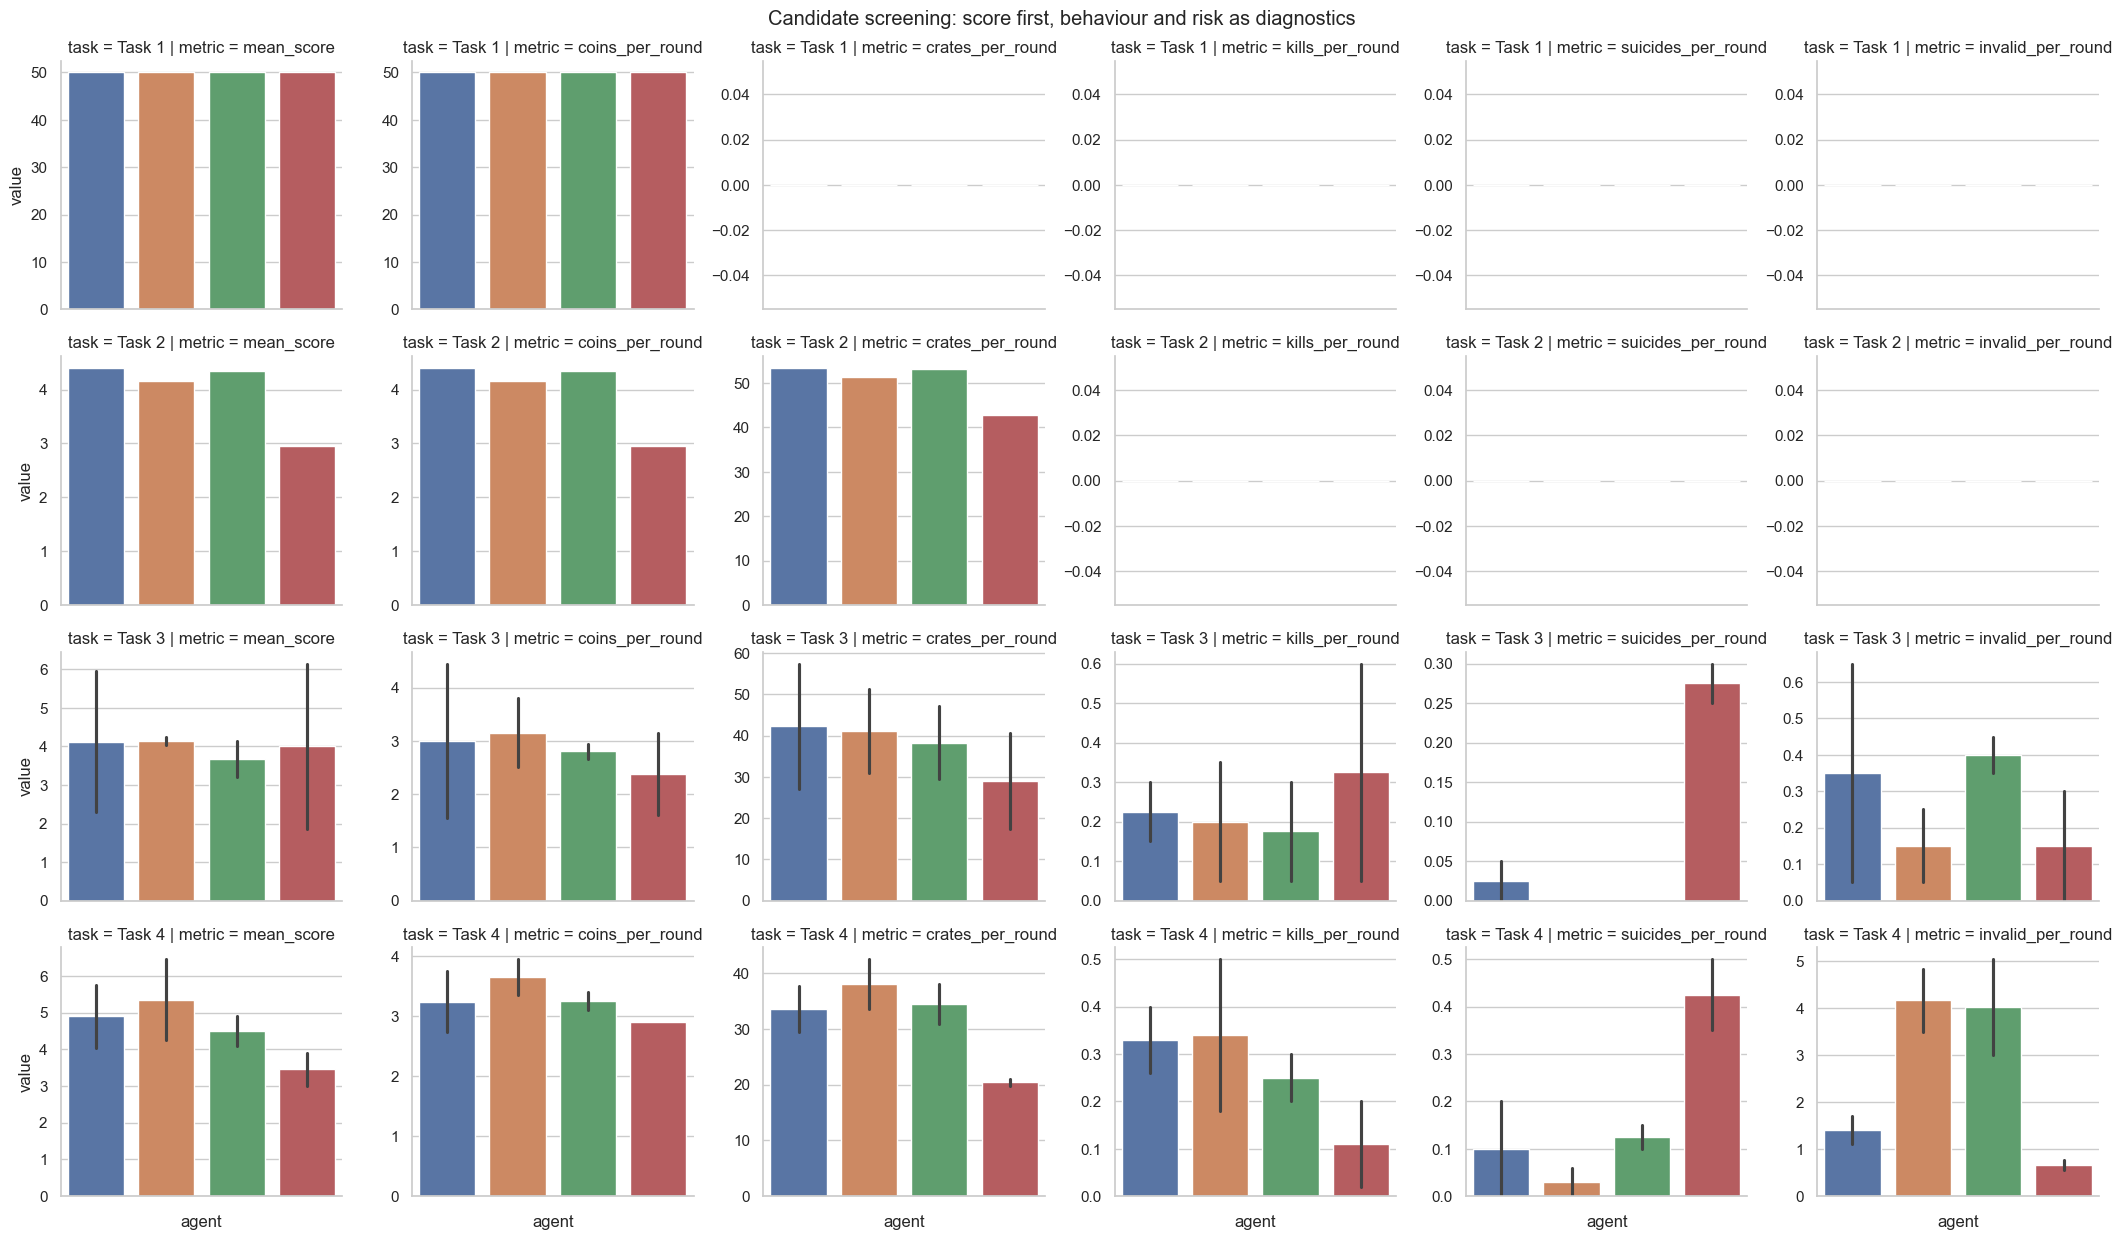

Task-4 promotion ranking (preliminary; fixed seed only):


,agent,mean_score,coins_per_round,kills_per_round,suicides_per_round,invalid_per_round,mean_action_ms
10,frozen_ddqn_day7,4.26,3.36,0.18,0.06,4.84,2.464
16,frozen_ddqn_day11,4.10,3.10,0.20,0.10,5.04,2.478
4,dueling_ddqn_agent,4.04,2.74,0.26,0.20,1.70,2.359
22,linear_q_agent,3.00,2.90,0.02,0.50,0.78,1.306


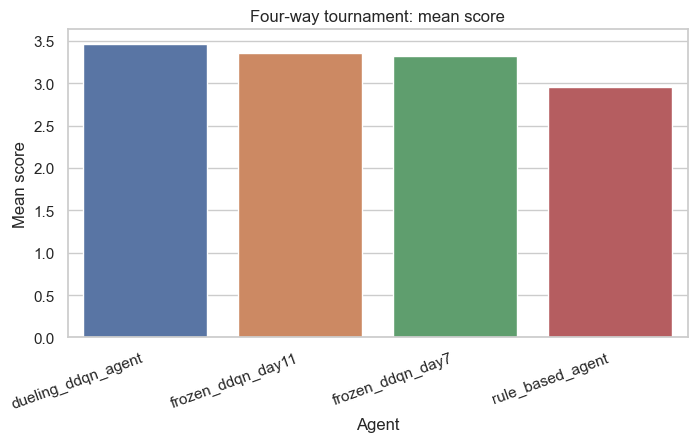

In [14]:
if not suite_table.empty:
    plot_cols = ['mean_score', 'coins_per_round', 'crates_per_round', 'kills_per_round',
                 'suicides_per_round', 'invalid_per_round']
    long = suite_table.melt(id_vars=['agent', 'task', 'lineup'], value_vars=plot_cols,
                            var_name='metric', value_name='value')
    g = sns.catplot(data=long, x='agent', y='value', hue='agent', col='metric', row='task',
                    kind='bar', sharey=False, height=3.1, aspect=1.15, legend=False)
    g.set_xticklabels(rotation=25, ha='right')
    g.fig.suptitle('Candidate screening: score first, behaviour and risk as diagnostics', y=1.01)
    plt.show()

    task4 = suite_table.query("task == 'Task 4' and lineup == 'rule_based'").copy()
    shortlist = task4.sort_values(['mean_score', 'suicides_per_round', 'invalid_per_round'],
                                  ascending=[False, True, True])
    print('Task-4 promotion ranking (preliminary; fixed seed only):')
    display(shortlist[['agent', 'mean_score', 'coins_per_round', 'kills_per_round',
                       'suicides_per_round', 'invalid_per_round', 'mean_action_ms']].round(3))

if not four_way_table.empty:
    plt.figure(figsize=(8, 4))
    sns.barplot(data=four_way_table, x='agent', y='mean_score', hue='agent', legend=False)
    plt.title('Four-way tournament: mean score')
    plt.xlabel('Agent')
    plt.ylabel('Mean score')
    plt.xticks(rotation=20, ha='right')
    plt.show()

## 8. What to optimise next

After reviewing the tables, select only the best two or three agents. For each, write one diagnosis before editing code:

- high Task-1 score but low Task-4 score → competitive play, survival, or opponent interaction;
- low crates in Task 2 → exploration, bomb placement, or post-bomb escape;
- good Task 3 but weak Task 4 → handling aggressive rule-based opponents;
- high suicides or invalid actions → safety mask/action validity before reward tuning;
- good score with slow decisions → simplify inference or profile the action path.

Change one mechanism per experiment, evaluate on development seeds, and only then confirm a candidate on new locked Task-4 seeds.